# Singular Value Decomposition and Regression

A computational companion to [Special Topics](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html), concentrating on its SVD and regression core. Explore how singular vectors describe geometry, reveal rank, compress matrix data, and separate a fitted vector from its coefficients.

The deck supplies the mathematical exposition. Predict each result before running its cell; the computations check concrete examples, while the plots illustrate their geometry. All data are generated in this notebook.

## Running this notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/11-special-topics.ipynb)

Run all cells in order with the **qmcpy** kernel. The setup cell changes the environment only in Colab, where it installs the course's recorded `classlib` checkout. It leaves the working directory unchanged. Colab does not save edits to the course repository; save a copy in Drive to retain your experiments.

Useful companions: [Eigenvalues and Eigenvectors](https://github.com/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/09-eigenvalues-and-eigenvectors.ipynb), [Inner Product Spaces](https://github.com/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/10-inner-product-spaces.ipynb), and [Matrix Spaces and Rank](https://github.com/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/08-matrix-spaces-and-rank.ipynb).

In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib; this may take a minute …")
    course_checkout = Path("/content/MATH332Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH332Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "submodule", "update", "--init", "--recursive", "classlib",
        ],
        check=True,
    )
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", str(course_checkout / "classlib")],
        check=True,
    )
    print("Colab setup complete.")

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import classlib as cl
from IPython.display import display, Markdown

%matplotlib inline
cl.nbviz.init(use_tex=False)
np.set_printoptions(precision=5, suppress=True)
colors = [cl.nbviz.TOL_BRIGHT[name] for name in ("blue", "red", "green", "purple")]

def show_matrix(label, value, digits=5):
    display(Markdown(label))
    display(sp.Matrix(np.round(np.asarray(value), digits)))

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

def full_svd(matrix):
    """Return full factors, singular values, and the usual numerical-rank cutoff."""
    U, singular_values, Vt = np.linalg.svd(matrix, full_matrices=True)
    cutoff = max(matrix.shape) * np.finfo(float).eps * singular_values[0] if singular_values.size else 0.0
    rank = int(np.count_nonzero(singular_values > cutoff))
    return U, singular_values, Vt, rank


## 1. A rectangular matrix stretches two directions

Use the deck's $3\times2$ matrix. NumPy returns `U, s, Vt`, with singular values in decreasing order. `Vt` is $\mathsf{V}^{\top}$, not $\mathsf{V}$.

Compare full and compact shapes. The compact SVD retains the $r$ positive stretches; the extra columns in the full orthogonal factors will later identify null spaces.

[Deck: The SVD separates directions from scale](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#the-svd-separates-directions-from-scale)

In [3]:
A = np.array([[3., 0.], [0., 0.], [0., 2.]])
U, s, Vt, rank = full_svd(A)
Ur, sr, Vrt = U[:, :rank], s[:rank], Vt[:rank, :]
Sigma_full = np.zeros(A.shape)
Sigma_full[np.arange(len(s)), np.arange(len(s))] = s
show_table(["Factor", "Full shape", "Compact shape"], [
    ["U", U.shape, Ur.shape],
    ["Sigma", Sigma_full.shape, (rank, rank)],
    ["V transpose", Vt.shape, Vrt.shape],
])
show_matrix("Compact output directions U_r", Ur)
show_matrix("Singular values", sr)
show_matrix("Compact input-coordinate map V_r transpose", Vrt)
assert np.allclose(U @ Sigma_full @ Vt, A)
assert np.allclose((Ur * sr) @ Vrt, A)
assert np.allclose(U.T @ U, np.eye(3))
assert np.allclose(Vt @ Vt.T, np.eye(2))
assert np.allclose(A @ Vrt.T, Ur * sr)
assert np.allclose(A.T @ Ur, Vrt.T * sr)
print("Full and compact reconstruction and both singular-vector equations pass.")

| Factor | Full shape | Compact shape |
| --- | --- | --- |
| U | (3, 3) | (3, 2) |
| Sigma | (3, 2) | (2, 2) |
| V transpose | (2, 2) | (2, 2) |

Compact output directions U_r

Matrix([
[1.0,  0.0],
[0.0,  0.0],
[0.0, -1.0]])

Singular values

Matrix([
[3.0],
[2.0]])

Compact input-coordinate map V_r transpose

Matrix([
[1.0,  0.0],
[0.0, -1.0]])

Full and compact reconstruction and both singular-vector equations pass.


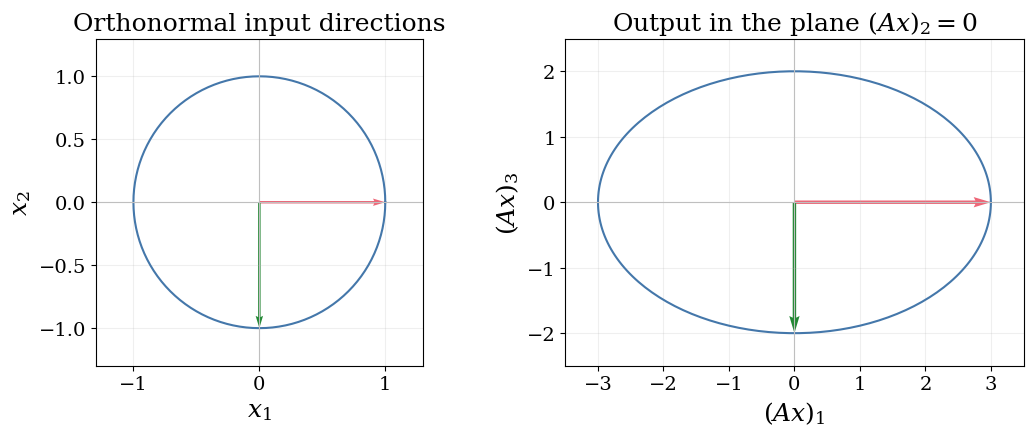

In [4]:
angle = np.linspace(0, 2 * np.pi, 241)
circle = np.vstack((np.cos(angle), np.sin(angle)))
ellipse = A @ circle
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(*circle, color=colors[0], label="unit input circle")
axes[1].plot(ellipse[0], ellipse[2], color=colors[0], label="output ellipse")
for j in range(rank):
    v = Vrt[j]
    stretched = sr[j] * Ur[:, j]
    axes[0].quiver(0, 0, *v, angles="xy", scale_units="xy", scale=1, color=colors[j + 1])
    axes[1].quiver(0, 0, stretched[0], stretched[2], angles="xy", scale_units="xy", scale=1, color=colors[j + 1])
for ax in axes:
    ax.axhline(0, color="0.75", linewidth=0.8)
    ax.axvline(0, color="0.75", linewidth=0.8)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
axes[0].set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="Orthonormal input directions", xlim=(-1.3, 1.3), ylim=(-1.3, 1.3))
axes[1].set(xlabel=r"$(Ax)_1$", ylabel=r"$(Ax)_3$", title=r"Output in the plane $(Ax)_2=0$", xlim=(-3.5, 3.5), ylim=(-2.5, 2.5))
fig.tight_layout()
plt.show()
assert np.allclose(ellipse[1], 0)


## 2. Full orthogonal factors recover the four spaces

Return to the $3\times4$ matrix from [Matrix Spaces and Rank](https://fjhickernell.github.io/MATH332Fall2026/slides/08-matrix-spaces-and-rank.html). Before running, predict its rank and the dimensions of $\operatorname{col}(\mathsf{B})$, $\operatorname{row}(\mathsf{B})$, $\operatorname{null}(\mathsf{B})$, and $\operatorname{null}(\mathsf{B}^{\top})$.

SVD bases may differ from the earlier echelon-based bases. Compare their spans rather than requiring identical vectors. Singular-vector signs may also change without changing the factorization.

In [5]:
B = np.array([[1., 2., 1., 3.], [2., 4., 0., 4.], [1., 2., 2., 4.]])
Ub, sb, Vbt, rb = full_svd(B)
column_basis = Ub[:, :rb]
row_basis = Vbt[:rb, :].T
null_basis = Vbt[rb:, :].T
left_null_basis = Ub[:, rb:]
show_table(["Space", "Ambient dimension", "Basis dimension"], [
    ["col(B)", B.shape[0], column_basis.shape[1]],
    ["row(B)", B.shape[1], row_basis.shape[1]],
    ["null(B)", B.shape[1], null_basis.shape[1]],
    ["null(B transpose)", B.shape[0], left_null_basis.shape[1]],
])
for label, basis in [("Column-space basis", column_basis), ("Row-space basis", row_basis),
                     ("Null-space basis", null_basis), ("Left-null-space basis", left_null_basis)]:
    show_matrix(label, basis)
assert rb == 2
assert np.allclose(B @ null_basis, 0)
assert np.allclose(B.T @ left_null_basis, 0)
assert np.allclose(row_basis.T @ null_basis, 0)
assert np.allclose(column_basis.T @ left_null_basis, 0)
assert np.allclose(column_basis @ column_basis.T @ B, B)
assert np.allclose(B @ row_basis @ row_basis.T, B)
print("Null-space equations, perpendicular pairs, and spanning projections pass.")

| Space | Ambient dimension | Basis dimension |
| --- | --- | --- |
| col(B) | 3 | 2 |
| row(B) | 4 | 2 |
| null(B) | 4 | 2 |
| null(B transpose) | 3 | 1 |

Column-space basis

Matrix([
[0.45476, 0.17687],
[0.68803, -0.6921],
[0.56552,  0.6998]])

Row-space basis

Matrix([
[0.28258,   -0.251],
[0.56517, -0.50201],
[  0.187,  0.77967],
[0.75217,  0.27766]])

Null-space basis

Matrix([
[ 0.90861,  0.17769],
[-0.19206, -0.62585],
[ 0.26224,   -0.537],
[-0.26224,    0.537]])

Left-null-space basis

Matrix([
[-0.87287],
[ 0.21822],
[ 0.43644]])

Null-space equations, perpendicular pairs, and spanning projections pass.


## 3. Rank-one sums give controlled approximations

For the deck's practice singular values $8,3,1$, predict the rank-one spectral error and the rank-two Frobenius error. Then compare measured errors with the first omitted singular value and the square root of the omitted squared values.

[Deck: The best low-rank approximation has a measurable error](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#the-best-low-rank-approximation-has-a-measurable-error)

In [6]:
C = np.vstack((np.diag([8., 3., 1.]), np.zeros((1, 3))))
Uc, sc, Vct = np.linalg.svd(C, full_matrices=False)
rank_one_terms = [sc[j] * np.outer(Uc[:, j], Vct[j]) for j in range(len(sc))]
assert np.allclose(sum(rank_one_terms), C)
rows = []
for k in range(len(sc) + 1):
    Ck = (Uc[:, :k] * sc[:k]) @ Vct[:k]
    spectral_error = np.linalg.norm(C - Ck, 2)
    frobenius_error = np.linalg.norm(C - Ck, "fro")
    predicted_spectral = sc[k] if k < len(sc) else 0.0
    predicted_frobenius = np.linalg.norm(sc[k:])
    assert np.isclose(spectral_error, predicted_spectral)
    assert np.isclose(frobenius_error, predicted_frobenius)
    rows.append([k, f"{spectral_error:.5f}", f"{frobenius_error:.5f}"])
show_table(["Retained rank k", "Spectral error", "Frobenius error"], rows)

| Retained rank k | Spectral error | Frobenius error |
| --- | --- | --- |
| 0 | 8.00000 | 8.60233 |
| 1 | 3.00000 | 3.16228 |
| 2 | 1.00000 | 1.00000 |
| 3 | 0.00000 | 0.00000 |

### A generated image makes the tradeoff visible

This grayscale array combines smooth shading with sharp edges; it is not downloaded from a website. Keeping $k$ singular directions stores $k(m+n+1)$ scalar values instead of $mn$. This count describes mathematical factors, not a compressed image file: metadata, quantization, and file formats have their own costs.

Predict which features will survive low-rank approximation. The same color range is used for every reconstruction.

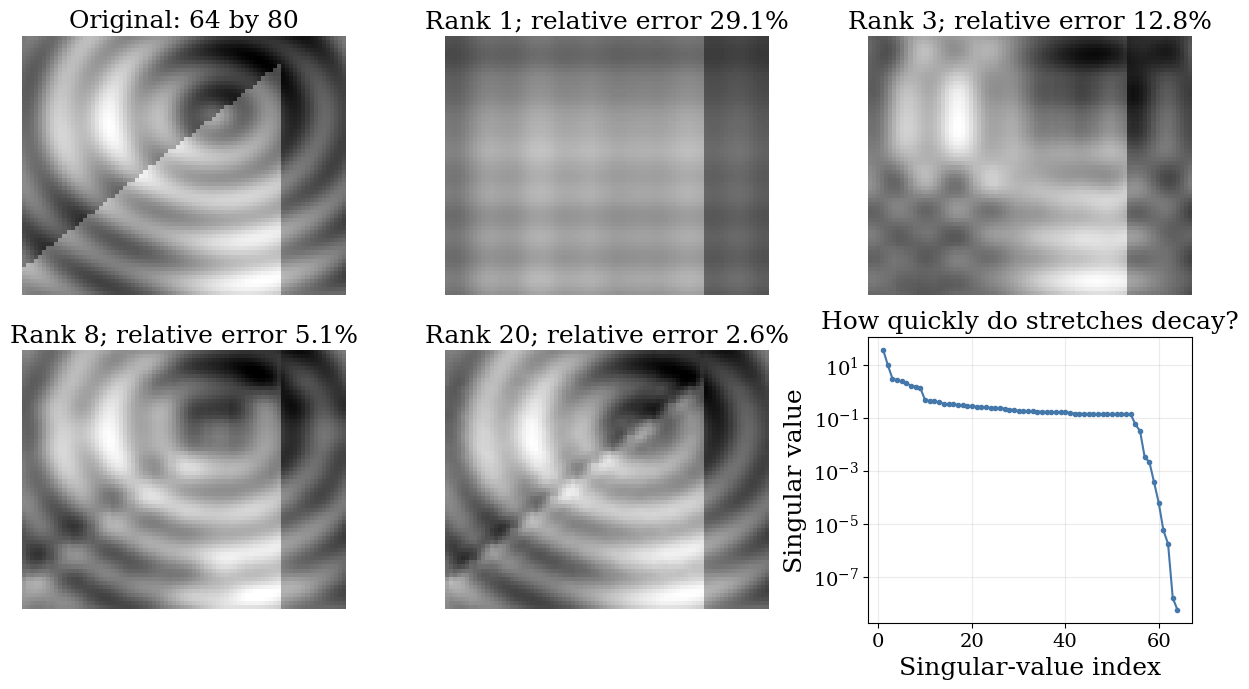

| Rank | Factor scalars | Fraction of original scalars | Relative Frobenius error |
| --- | --- | --- | --- |
| 1 | 145 | 2.8% | 29.15% |
| 3 | 435 | 8.5% | 12.79% |
| 8 | 1160 | 22.7% | 5.15% |
| 20 | 2900 | 56.6% | 2.62% |

In [7]:
height, width = 64, 80
x = np.linspace(0, 1, width)
y = np.linspace(0, 1, height)
xx, yy = np.meshgrid(x, y)
image = (0.4 + 0.25 * np.sin(2 * np.pi * xx) * np.cos(np.pi * yy)
         + 0.4 * np.exp(-18 * ((xx - 0.25)**2 + (yy - 0.4)**2))
         + 0.25 * ((xx + yy > 0.9) & (xx < 0.8))
         + 0.1 * np.cos(12 * np.pi * np.sqrt((xx - 0.6)**2 + (yy - 0.3)**2)))
image = (image - image.min()) / (image.max() - image.min())
Ui, si, Vit = np.linalg.svd(image, full_matrices=False)
kept_ranks = [1, 3, 8, 20]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Original: {height} by {width}")
rows = []
for ax, k in zip(axes[1:5], kept_ranks):
    reconstruction = (Ui[:, :k] * si[:k]) @ Vit[:k]
    error = np.linalg.norm(image - reconstruction, "fro")
    relative_error = error / np.linalg.norm(image, "fro")
    scalar_count = k * (height + width + 1)
    assert np.isclose(error, np.linalg.norm(si[k:]))
    ax.imshow(reconstruction, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Rank {k}; relative error {relative_error:.1%}")
    rows.append([k, scalar_count, f"{scalar_count / image.size:.1%}", f"{relative_error:.2%}"])
for ax in axes[:5]:
    ax.set_axis_off()
axes[5].semilogy(np.arange(1, len(si) + 1), si, "o-", markersize=3, color=colors[0])
axes[5].set(xlabel="Singular-value index", ylabel="Singular value", title="How quickly do stretches decay?")
axes[5].grid(alpha=0.25)
fig.tight_layout()
plt.show()
show_table(["Rank", "Factor scalars", "Fraction of original scalars", "Relative Frobenius error"], rows)


## 4. A unique fitted vector can have many coefficient lists

Use the deck's duplicate-feature example
$\mathsf{D}=\begin{bmatrix}1&1\\1&1\end{bmatrix}$ and
$b=\begin{bmatrix}2\\4\end{bmatrix}$.
The pseudoinverse reverses its one positive stretch. Predict the fitted vector, its residual, and which combination of the two coefficients is determined.

[Deck: The pseudoinverse reverses the nonzero stretches](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#the-pseudoinverse-reverses-the-nonzero-stretches)

In [8]:
D = np.array([[1., 1.], [1., 1.]])
b = np.array([2., 4.])
Ud, sd, Vdt, rd = full_svd(D)
D_pinv = (Vdt[:rd].T / sd[:rd]) @ Ud[:, :rd].T
x_min = D_pinv @ b
fitted = D @ x_min
residual = b - fitted
show_matrix("Pseudoinverse D dagger", D_pinv)
show_matrix("Minimum-norm coefficients", x_min)
show_matrix("Fitted vector", fitted)
show_matrix("Residual", residual)
assert np.allclose(D_pinv, np.linalg.pinv(D))
assert np.allclose(x_min, [1.5, 1.5])
assert np.allclose(fitted, [3., 3.])
assert np.allclose(D.T @ residual, 0)
assert np.allclose(D @ D_pinv @ D, D)
assert np.allclose(D_pinv @ D @ D_pinv, D_pinv)
print(f"Identifiable coefficient sum: {x_min.sum():.5f}")

Pseudoinverse D dagger

Matrix([
[0.25, 0.25],
[0.25, 0.25]])

Minimum-norm coefficients

Matrix([
[1.5],
[1.5]])

Fitted vector

Matrix([
[3.0],
[3.0]])

Residual

Matrix([
[-1.0],
[ 1.0]])

Identifiable coefficient sum: 3.00000


### Move along the null space

Every least-squares minimizer has the form
$\widehat{x}+t\begin{bmatrix}1\\-1\end{bmatrix}$.
Predict what happens to the residual norm and the coefficient norm as $t$ changes. A fit and the coefficients used to represent it answer different questions.

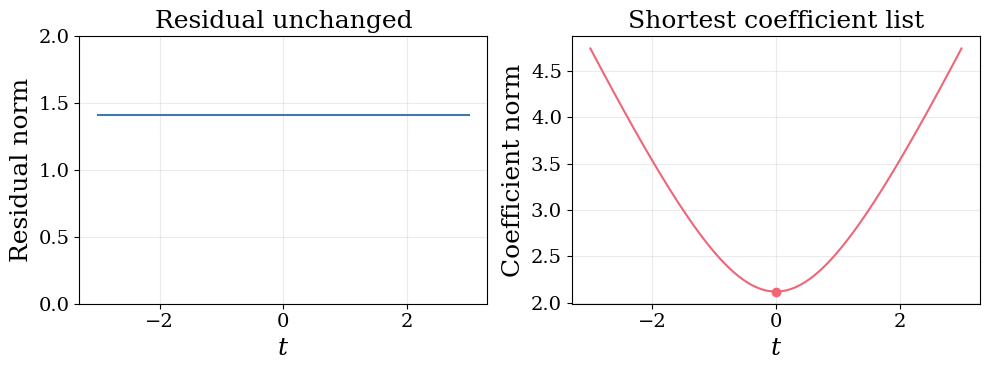

In [9]:
parameters = np.linspace(-3, 3, 121)
null_direction = np.array([1., -1.])
coefficient_lists = x_min[:, None] + null_direction[:, None] * parameters
all_fits = D @ coefficient_lists
residual_norms = np.linalg.norm(b[:, None] - all_fits, axis=0)
coefficient_norms = np.linalg.norm(coefficient_lists, axis=0)
assert np.allclose(D @ null_direction, 0)
assert np.allclose(all_fits, fitted[:, None])
assert np.allclose(coefficient_norms**2, np.linalg.norm(x_min)**2 + 2 * parameters**2)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(parameters, residual_norms, color=colors[0])
axes[0].set(xlabel=r"$t$", ylabel="Residual norm", title="Residual unchanged", ylim=(0, 2))
axes[1].plot(parameters, coefficient_norms, color=colors[1])
axes[1].scatter([0], [np.linalg.norm(x_min)], color=colors[1], zorder=3)
axes[1].set(xlabel=r"$t$", ylabel="Coefficient norm", title="Shortest coefficient list")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 5. Nearly redundant features amplify small data changes

The next two columns are independent but very close. This model fits through the origin; it has no intercept. Its two slope coefficients are known only because we generated the data ourselves.

Add a small response perturbation along the weakest left singular vector, plus a still smaller perpendicular component. Predict which input direction changes most and which part of the perturbation cannot be fitted.

[Deck: Small singular values amplify data perturbations](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#small-singular-values-amplify-data-perturbations)

In [10]:
t = np.linspace(-1, 1, 21)
A_near = np.column_stack((t, t + 0.002 * np.sin(np.pi * t)))
x_true = np.array([2., -1.])
b_clean = A_near @ x_true
Un, sn, Vnt, rn = full_svd(A_near)
assert rn == 2
response_change = 0.02 * Un[:, 1] + 0.005 * Un[:, 2]
b_observed = b_clean + response_change
x_ls = np.linalg.lstsq(A_near, b_observed, rcond=None)[0]
predicted_change = (0.02 / sn[1]) * Vnt[1]
assert np.allclose(x_ls - x_true, predicted_change)
assert np.isclose(np.linalg.norm(A_near @ x_ls - b_observed), 0.005)
assert np.allclose(A_near.T @ (b_observed - A_near @ x_ls), 0)
show_table(["Quantity", "Value"], [
    ["Singular values", np.array2string(sn)],
    ["2-norm condition number", f"{sn[0] / sn[1]:.2f}"],
    ["Response perturbation norm", f"{np.linalg.norm(response_change):.5f}"],
    ["Coefficient-change norm", f"{np.linalg.norm(x_ls - x_true):.5f}"],
])
show_matrix("Generating coefficients", x_true)
show_matrix("Least-squares coefficients after perturbation", x_ls)


| Quantity | Value |
| --- | --- |
| Singular values | [3.9275 0.0031] |
| 2-norm condition number | 1265.62 |
| Response perturbation norm | 0.02062 |
| Coefficient-change norm | 6.44490 |

Generating coefficients

Matrix([
[ 2.0],
[-1.0]])

Least-squares coefficients after perturbation

Matrix([
[ 6.56096],
[-5.55349]])

## 6. Truncation and ridge trade data fit for coefficient control

Use the same observations. Truncated SVD discards stretches below a threshold; ridge multiplies each singular-coordinate response by $\sigma_j/(\sigma_j^2+\lambda)$ instead of $1/\sigma_j$.

Here ridge penalizes **both** coefficients, with no intercept to exempt. The chosen threshold and penalty illustrate the algebra; they are not automatically appropriate for other data. The generating-coefficient error is observable only in this synthetic example. In an application, select tuning parameters using appropriate noise information or validation data.

[Deck: Truncation and ridge control small stretches](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#truncation-and-ridge-control-small-stretches)

| Method | Coefficients | Residual norm | Coefficient norm | Error from generating coefficients |
| --- | --- | --- | --- | --- |
| Least squares | [ 6.561  -5.5535] | 0.00500 | 8.59578 | 6.44490 |
| Truncated SVD | [0.4984 0.4992] | 0.02705 | 0.70537 | 2.12190 |
| Ridge | [ 1.0309 -0.0325] | 0.02476 | 1.03142 | 1.36938 |

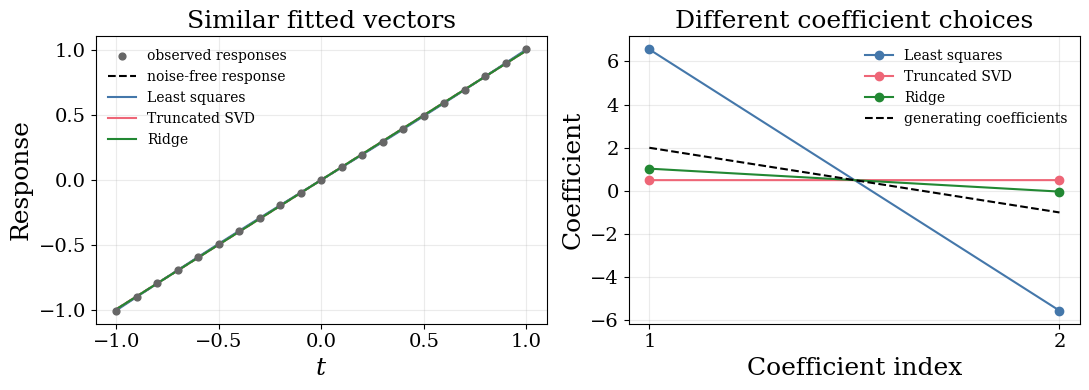

In [11]:
threshold = 0.01
ridge_penalty = 1e-4
spectral_response = Un[:, :rn].T @ b_observed
retained = sn[:rn] > threshold
x_tsvd = Vnt[:rn][retained].T @ (spectral_response[retained] / sn[:rn][retained])
x_ridge = Vnt[:rn].T @ ((sn[:rn] / (sn[:rn]**2 + ridge_penalty)) * spectral_response)
# The augmented least-squares problem checks the ridge objective without a matrix inverse.
x_ridge_augmented = np.linalg.lstsq(
    np.vstack((A_near, np.sqrt(ridge_penalty) * np.eye(2))),
    np.concatenate((b_observed, np.zeros(2))), rcond=None,
)[0]
assert np.allclose(A_near @ x_tsvd, Un[:, :rn][:, retained] @ spectral_response[retained])
assert np.allclose(x_ridge, x_ridge_augmented)
assert np.allclose((A_near.T @ A_near + ridge_penalty * np.eye(2)) @ x_ridge,
                   A_near.T @ b_observed)
methods = [("Least squares", x_ls), ("Truncated SVD", x_tsvd), ("Ridge", x_ridge)]
rows = []
for name, coefficients in methods:
    rows.append([name, np.array2string(coefficients, precision=4),
                 f"{np.linalg.norm(A_near @ coefficients - b_observed):.5f}",
                 f"{np.linalg.norm(coefficients):.5f}",
                 f"{np.linalg.norm(coefficients - x_true):.5f}"])
show_table(["Method", "Coefficients", "Residual norm", "Coefficient norm", "Error from generating coefficients"], rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(t, b_observed, color="0.4", s=24, label="observed responses", zorder=3)
axes[0].plot(t, b_clean, color="black", linestyle="--", label="noise-free response")
for j, (name, coefficients) in enumerate(methods):
    axes[0].plot(t, A_near @ coefficients, color=colors[j], label=name)
    axes[1].plot([1, 2], coefficients, "o-", color=colors[j], label=name)
axes[0].set(xlabel=r"$t$", ylabel="Response", title="Similar fitted vectors")
axes[1].plot([1, 2], x_true, "k--", label="generating coefficients")
axes[1].set(xticks=[1, 2], xlabel="Coefficient index", ylabel="Coefficient", title="Different coefficient choices")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=10)
fig.tight_layout()
plt.show()


## Your experiments

1. Replace the first rectangular matrix by $\begin{bmatrix}3&0\\0&0\\0&0\end{bmatrix}$. Predict the image of the circle and the nullity before recomputing its SVD. Which full-factor columns supply the missing directions?
2. Add a third identical column to the duplicate-feature regression example. Predict how the minimum-norm coefficient total is divided. Check that the fitted vector stays unchanged.
3. Change the generated image's sharp-edge amplitude and compare the retained rank needed for 1% relative Frobenius error. Count factor scalars as well as error; a factorization is not a smaller representation at every rank.
4. In the nearly redundant-feature example, change `0.002` to another small positive value and rerun Sections 5–6. Compare singular values, coefficient changes, and residuals. Try several thresholds and ridge penalties; explain the information each method discards or shrinks.

When changing a matrix, also update any example-specific expected values and dimensions in its checks.

Use the [deck's SVD and regression summary](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html#big-ideas) to explain the numerical results in terms of subspaces, orthogonal coordinates, and stretches.

In [12]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print(
    "Total execution time for this notebook is "
    f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec."
)

Total execution time for this notebook is 0 min 1.4 sec.
